# 1. Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import shutil
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


Downloading the CSV data set files as API

In [2]:

# Download latest version
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")

# Copy files to /content/sample_data
destination = "/content/sample_data"
for filename in os.listdir(path):
    shutil.copy(os.path.join(path, filename), destination)

print("Dataset copied to:", destination)

Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.
Dataset copied to: /content/sample_data


# 2. Load Dataset

In [6]:

# Load the dataset /healthcare-dataset-stroke-data.csv
df = pd.read_csv("/content/sample_data/healthcare-dataset-stroke-data.csv")

# Display the first 5 rows
df.head()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


# 3. Exploratory Data Analysis (EDA)

In [7]:
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()


Dataset shape: (5110, 12)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [8]:
# Count missing values in each column
print(df.isnull().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


### 3A. Examine Target Class Distribution
Check for **class imbalance** by comparing the number of positive (`1`) and negative (`0`) stroke cases. If one class heavily outweighs the other, a naive model could predict "no stroke" for every patient and still achieve high accuracy while failing to catch actual at-risk cases.

---



stroke
0    4861
1     249
Name: count, dtype: int64


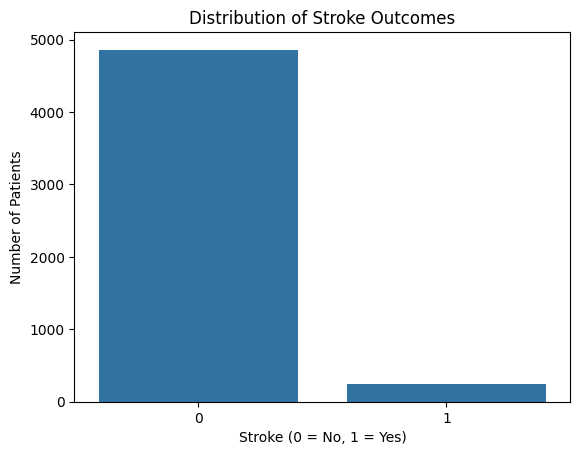

In [9]:
# Count how many records belong to each class
print(df["stroke"].value_counts())

# Visualize the distribution
sns.countplot(data=df, x="stroke")

plt.title("Distribution of Stroke Outcomes")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()


### 3B. Examine age distribution

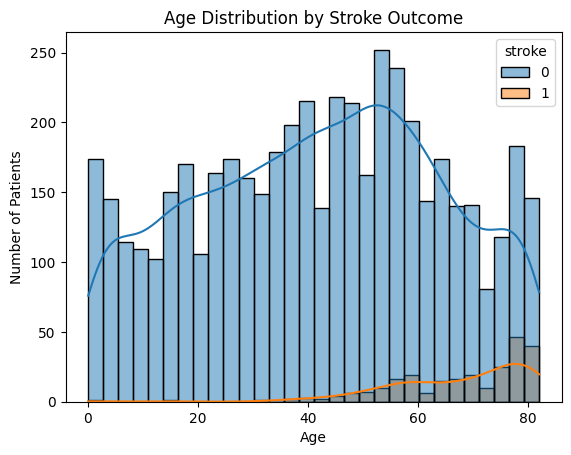

In [10]:

sns.histplot(data=df, x="age", hue="stroke", bins=30, kde=True)

plt.title("Age Distribution by Stroke Outcome")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()


### 3C. Examine numerical correlations

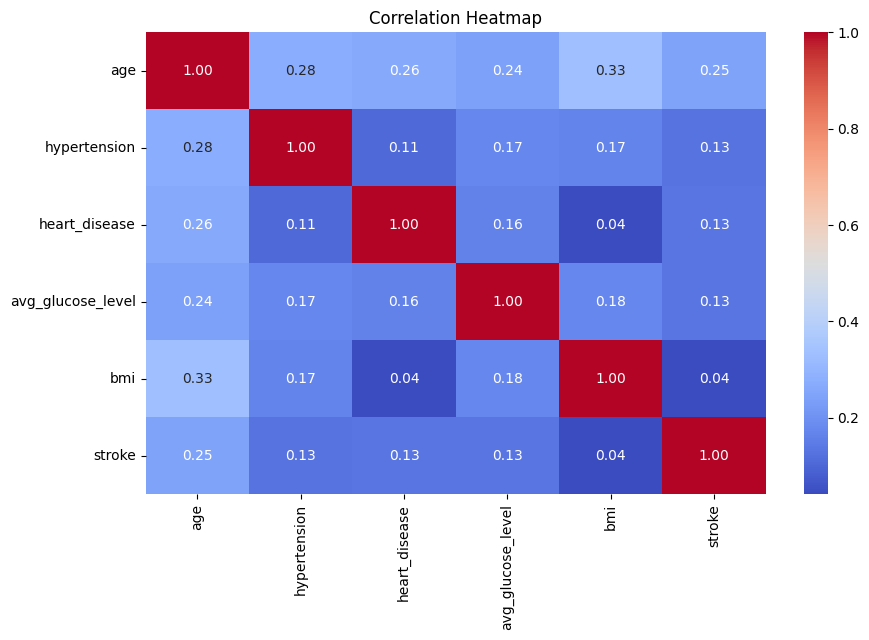

In [12]:

# Select numerical columns
numeric_df = df.select_dtypes(include=["number"]).drop(columns=["id"])

# Create correlation heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


# 4. Data Preprocessing

# 4A. Remove the ID column

The ID is simply an identifier for each patient. It doesn't provide useful medical information for our prediction.

In [13]:
# Remove patient ID
df = df.drop(columns=["id"])

print("ID column removed.")
df.head()

ID column removed.
   gender   age  hypertension  heart_disease ever_married      work_type  \
0    Male  67.0             0              1          Yes        Private   
1  Female  61.0             0              0          Yes  Self-employed   
2    Male  80.0             0              1          Yes        Private   
3  Female  49.0             0              0          Yes        Private   
4  Female  79.0             1              0          Yes  Self-employed   

  Residence_type  avg_glucose_level   bmi   smoking_status  stroke  
0          Urban             228.69  36.6  formerly smoked       1  
1          Rural             202.21   NaN     never smoked       1  
2          Rural             105.92  32.5     never smoked       1  
3          Urban             171.23  34.4           smokes       1  
4          Rural             174.12  24.0     never smoked       1  


## 4B. Separate numerical and categorical columns
The dataset contains both numerical measurements and categorical variables (such as gender, smoking status, and work type). We'll separate them into distinct feature groups so we can apply the right preprocessing steps to each.

In [15]:

# Identify numerical and categorical columns
numeric_features = df.select_dtypes(include=["int64", "float64"]).columns.drop("stroke")

categorical_features = df.select_dtypes(include=["object"]).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))


Numerical Features:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

Categorical Features:
['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


# 4C. Create preprocessing pipelines

important part of machine learning.

Model will use use:
- Median imputation for missing numerical values.
- Most-frequent imputation for missing categorical values.
- StandardScaler to scale numerical features.
- OneHotEncoder to convert categorical features into numerical representations.

### Example: Before vs. After Preprocessing

**Before (Raw Patient Record):**
| age | bmi | gender |
| :--- | :--- | :--- |
| 61.0 | `NaN` | Female |

**After (Imputed, Scaled & Encoded):**
| age (scaled) | bmi (imputed + scaled) | gender_Female | gender_Male |
| :--- | :--- | :--- | :--- |
| `0.78` | `-0.12` | `1.0` | `0.0` |

* **Missing BMI (`NaN`):** Replaced with the training set median (`28.1`), then standardized.
* **Text Category (`Female`):** Converted into binary columns (`1.0` / `0.0`) via one-hot encoding.

The pipeline will learn these transformations from the training data only. This helps prevent data leakage.

In [16]:

# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


## 5. Train-Test Split
The model will use an 80/20 split:
* **80%** of the data will train the model.
* **20%** will test the model on records it hasn't seen before.

### Variable Breakdown
| Variable | Meaning |
| :--- | :--- |
| `X` | Patient characteristics (features) |
| `y` | Stroke outcome (target) |
| `X_train` | Patient characteristics used for training (80%) |
| `X_test` | Patient characteristics used for testing (20%) |
| `y_train` | Actual stroke outcomes for training (80%) |
| `y_test` | Actual stroke outcomes for testing (20%) |

> **Why `stratify=y` matters:** Because our dataset is heavily imbalanced (~95% non-stroke vs. ~5% stroke), setting `stratify=y` preserves that exact class ratio across both the training and testing splits.

In [17]:

# Separate features (X) and target (y)
X = df.drop(columns=["stroke"])
y = df["stroke"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining stroke distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting stroke distribution:")
print(y_test.value_counts(normalize=True))


Training records: 4088
Testing records: 1022

Training stroke distribution:
stroke
0    0.951321
1    0.048679
Name: proportion, dtype: float64

Testing stroke distribution:
stroke
0    0.951076
1    0.048924
Name: proportion, dtype: float64


# 6. Model Training

## 6A. Logistic Regression

### What's happening here?
* **Machine Learning Pipeline:** Combines our preprocessing steps (`preprocessor`) and classifier (`LogisticRegression`) into a single workflow.
* **Data Preparation:** Automatically imputes, scales, and encodes the patient features before passing them to the model.
* **Model Training (`.fit()`):** Logistic Regression learns patterns from `X_train` and `y_train` to predict stroke risk.

> **Why `class_weight="balanced"`?** Because our dataset is heavily imbalanced (~95% non-stroke vs. ~5% stroke), this parameter automatically assigns higher weight to the minority class (`stroke = 1`) so the model doesn't ignore rare positive cases.

In [25]:


# # Initialize with all default settings
# logistic_model = LogisticRegression()

# # Train directly on preprocessed data
# logistic_model.fit(X_train, y_train)

# Create Logistic Regression pipeline

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


## 6B. Random Forest
Random Forest builds an ensemble of multiple decision trees and combines their predictions to improve accuracy and reduce overfitting.

* **`n_estimators=100`:** Instructs the model to build and aggregate **100** individual decision trees.
* **`class_weight="balanced"`:** Adjusts tree weights inversely proportional to class frequencies so rare stroke cases aren't overlooked.

In [23]:

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


### Trained Models Ready for Evaluation
1. **Logistic Regression** (`logistic_model`)
2. **Random Forest** (`random_forest_model`)

# 7. Model Evaluation

## 7A. Generate predictions
The `.predict()` method takes the unseen test patient records (`X_test`) and generates a predicted stroke outcome for each patient:
* **`0`** — No stroke predicted
* **`1`** — Stroke predicted

In [26]:

# Generate predictions
logistic_predictions = logistic_model.predict(X_test)

random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions generated successfully!")


Predictions generated successfully!


## 7B. Compare model performance

### Evaluation Metrics
| Metric | Explanation |
| :--- | :--- |
| **Accuracy** | Percentage of all predictions that were correct |
| **Precision** | Of the predicted stroke cases, how many were actually stroke-positive? |
| **Recall** | Of the actual stroke-positive cases, how many did the model identify? |
| **F1-score** | Harmonic mean balancing precision and recall |

> **Why Recall vs. Precision matters here:** For stroke screening, **Recall** is critical because we want to catch as many actual stroke-positive cases as possible (`0.80` for Logistic Regression vs. `0.00` for Random Forest). However, high recall with very low precision (`0.1379`) also means many false alarms—so both metrics need to be weighed together.

In [27]:

def evaluate_model(model_name, actual, predicted):

    print("\nModel:", model_name)
    print("-" * 35)

    print("Accuracy:", round(accuracy_score(actual, predicted), 4))
    print("Precision:", round(precision_score(actual, predicted, zero_division=0), 4))
    print("Recall:", round(recall_score(actual, predicted, zero_division=0), 4))
    print("F1 Score:", round(f1_score(actual, predicted, zero_division=0), 4))


# Evaluate Logistic Regression
evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions
)

# Evaluate Random Forest
evaluate_model(
    "Random Forest",
    y_test,
    random_forest_predictions
)



Model: Logistic Regression
-----------------------------------
Accuracy: 0.7456
Precision: 0.1379
Recall: 0.8
F1 Score: 0.2353

Model: Random Forest
-----------------------------------
Accuracy: 0.9491
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


## 7C. Display confusion matrices

### Example Confusion Matrix
*(Illustrative numbers only, not actual model results)*

| | **Predicted 0** | **Predicted 1** |
| :--- | :---: | :---: |
| **Actual 0** | `950`<br>*True Negative* | `20`<br>*False Positive* |
| **Actual 1** | `30`<br>*False Negative* | `22`<br>*True Positive* |

### What Each Quadrant Means
* **True Positive (TP):** Correctly identified a stroke-positive record.
* **True Negative (TN):** Correctly identified a stroke-negative record.
* **False Positive (FP):** Predicted stroke, but the record was actually negative (false alarm).
* **False Negative (FN):** Failed to identify a stroke-positive record (missed case).

> **Why False Negatives matter most here:** In a medical screening context, missing an actual stroke risk (**False Negative**) carries far higher consequences than triggering a follow-up test (**False Positive**)—which is why we pay close attention to the bottom-left cell in our heatmaps below.

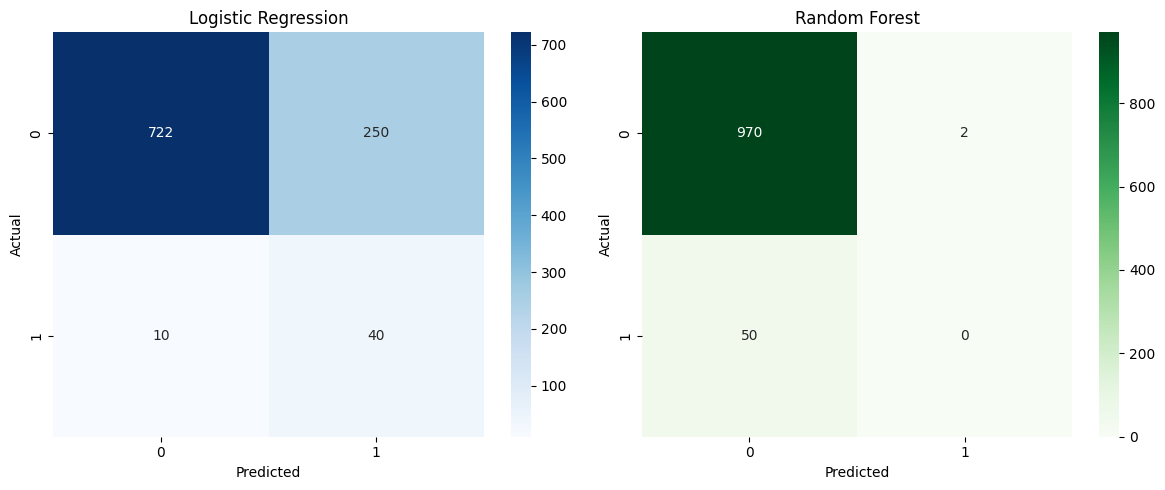

In [28]:

# Create side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
sns.heatmap(
    confusion_matrix(y_test, logistic_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest
sns.heatmap(
    confusion_matrix(y_test, random_forest_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


## Project Conclusion

In this project, I developed two machine learning
classification models to analyze patient health
characteristics and predict recorded stroke outcomes.

The models used were:
- Logistic Regression
- Random Forest

During data preprocessing, I handled missing values,
encoded categorical variables, and addressed class
imbalance using balanced class weights.

I evaluated both models using:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

### Results

When identifying recorded stroke-positive cases, **Logistic Regression** performed significantly better because it successfully identified positive cases rather than defaulting to the majority class.

- **Logistic Regression** achieved a **Recall of 0.80** (catching **40 out of 50** actual stroke-positive cases in the test set) and an **F1-score of 0.2353**. While its overall **Accuracy (0.7456)** and **Precision (0.1379)** were lower due to **250 false positives**, it effectively minimized dangerous false negatives (**10 missed cases**).
- **Random Forest** achieved a higher overall **Accuracy (0.9491)**, but scored **0.00 across Precision, Recall, and F1-score**. Even with balanced class weights, the model predicted "no stroke" for almost every patient (only **2** positive predictions, both false positives) and missed all **50** actual stroke cases—demonstrating how raw accuracy can be misleading on imbalanced medical datasets.

### Challenges

One of the main challenges was the imbalance
between stroke-positive and stroke-negative records.

### Limitations

The dataset is limited and may not represent the
general patient population. These models are
educational experiments and should not be used
for medical diagnosis or clinical decisions.

### Future Improvements

- Experiment with additional classification models.
- Explore feature importance.
- Experiment with different classification thresholds.
- Evaluate performance on additional datasets.


### Model Performance Analysis

Logistic Regression achieved 80% recall,
identifying 40 out of 50 stroke-positive
records in the test dataset.

However, its precision was relatively low
at 13.79%, indicating a high number of
false-positive predictions.

Random Forest achieved 94.91% accuracy,
but its recall was 0%. It failed to identify
any stroke-positive records.

This demonstrates why accuracy alone is
not a sufficient evaluation metric when
working with imbalanced medical datasets.

In this experiment, Logistic Regression
identified more positive cases than
Random Forest, although its high number
of false positives remains a limitation.
